# Houston Home Price Intelligence (Track 2)

**Goal:** train a model that estimates a *fair price* for a Houston home from its facts and location, then use it to
1. flag listings that look **underpriced or overpriced**, and
2. show the **true monthly cost** (mortgage + Texas property tax + insurance) so a buyer can search by budget, not sticker price.

**How to run:** `Runtime → Run all`. About 2–4 minutes on Colab's free CPU. No API keys needed.

| Step | What happens |
|---|---|
| 1 | Load the Kaggle dataset |
| 2 | Data checks: what is really in the file |
| 3 | Clean |
| 4 | Explore |
| 5 | Features: location, hub distances, neighborhood comps |
| 6 | Train & compare models (the before/after table judges want) |
| 7 | What drives Houston prices |
| 8 | Fair-value deal finder |
| 9 | Monthly-cost budget search |
| 10 | Save the model for an app |

In [1]:
!pip -q install kagglehub

import glob, os, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.model_selection import train_test_split, KFold
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neighbors import BallTree

SEED = 42
EARTH_MILES = 3958.8

# Major job centers (from the Challenge 2 brief)
HUBS = {
    "downtown": (29.7604, -95.3698),
    "tmc": (29.7079, -95.3978),
    "galleria": (29.7399, -95.4617),
    "energy_corridor": (29.7848, -95.6265),
    "uh": (29.7199, -95.3422),
}

# Chart style: one blue for single-series charts, a light->dark blue ramp for magnitude, quiet axes
BLUE, INK, INK_2, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df"
BLUE_RAMP = LinearSegmentedColormap.from_list(
    "blue_ramp", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": INK_2, "ytick.color": INK_2, "font.size": 10,
})
pd.set_option("display.max_columns", 50)

import sklearn
print(f"pandas {pd.__version__} | scikit-learn {sklearn.__version__} | numpy {np.__version__}")

pandas 3.1.0 | scikit-learn 1.9.1 | numpy 2.5.4


## 1. Load the data
Tries `kagglehub` first, then Kaggle's direct download URL. If both fail, upload `properties_clean_v2.csv`
(it's in the project's `data/raw/` folder) with the Files panel on the left and set `csv_path` to it.

In [2]:
KAGGLE_ID = "mohamedalmansop/houston-housing-market-2024-clean-dataset"
try:
    import kagglehub
    folder = kagglehub.dataset_download(KAGGLE_ID)
    csv_path = glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True)[0]
    raw = pd.read_csv(csv_path)
except Exception as err:
    print("kagglehub failed:", err, "\nTrying the direct URL...")
    try:
        csv_path = f"https://www.kaggle.com/api/v1/datasets/download/{KAGGLE_ID}"
        raw = pd.read_csv(csv_path, compression="zip")
    except Exception as err2:
        print("Direct download failed too:", err2)
        csv_path = "properties_clean_v2.csv"  # uploaded via the Files panel
        raw = pd.read_csv(csv_path)

print(f"Loaded {len(raw):,} rows x {raw.shape[1]} columns from {csv_path}")
raw.head()

<local path> AI Hackathon Fall 2026/track2-housing/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loaded 25,922 rows x 17 columns from ~/.cache/kagglehub/datasets/mohamedalmansop/houston-housing-market-2024-clean-dataset/versions/1/properties_clean_v2.csv


,zpid,price,bedrooms,bathrooms,livingArea,lotAreaValue,yearBuilt,homeType,latitude,longitude,city,zipcode,zestimate,rentZestimate,daysOnZillow,has_zestimate,has_rent_zestimate
0,305340899,450000,4.0,3.0,1943.0,6769.2240,2018.0,SINGLE_FAMILY,29.865578,-95.196150,Houston,77044,439700.0,2099.0,18,1,1
1,112161921,699000,4.0,4.0,4240.0,8385.3000,2010.0,SINGLE_FAMILY,29.954235,-95.165580,Houston,77044,680600.0,4099.0,11,1,1
2,89641740,535000,5.0,4.0,4603.0,9221.6520,2008.0,SINGLE_FAMILY,29.961273,-95.160866,Houston,77044,533700.0,4300.0,0,1,1
3,28549516,498000,5.0,3.0,3042.0,7993.2600,2000.0,SINGLE_FAMILY,29.932020,-95.185394,Houston,77044,498000.0,2998.0,0,1,1
4,123239699,725000,5.0,4.0,3969.0,0.3016,2015.0,SINGLE_FAMILY,29.968948,-95.157500,Houston,77044,696000.0,4505.0,89,1,1


In [3]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
zpid,25922.0,5.492932e+08,7.846160e+08,2.648851e+07,2.838337e+07,1.611158e+08,3.501943e+08,2.144636e+09
price,25922.0,5.412449e+05,9.316352e+05,8.500000e+03,2.790000e+05,3.799000e+05,5.400000e+05,6.900000e+07
bedrooms,25922.0,3.112684e+00,1.442544e+00,0.000000e+00,3.000000e+00,3.000000e+00,4.000000e+00,2.000000e+01
bathrooms,25922.0,2.646902e+00,1.480466e+00,0.000000e+00,2.000000e+00,3.000000e+00,3.000000e+00,3.600000e+01
livingArea,25922.0,2.160908e+03,1.483761e+03,0.000000e+00,1.472000e+03,2.077000e+03,2.767000e+03,4.809000e+04
lotAreaValue,25922.0,4.654046e+03,3.196890e+03,2.500000e-01,1.453000e+03,6.050484e+03,6.660324e+03,1.088564e+04
yearBuilt,25922.0,2.003114e+03,2.367525e+01,1.890000e+03,1.992000e+03,2.008000e+03,2.024000e+03,2.026000e+03
latitude,25922.0,2.983073e+01,2.071390e-01,2.941722e+01,2.968303e+01,2.981173e+01,3.000445e+01,3.026486e+01
longitude,25922.0,-9.546180e+01,2.232633e-01,-9.602179e+01,-9.563039e+01,-9.544060e+01,-9.531933e+01,-9.492529e+01
zipcode,25922.0,7.728293e+04,2.048493e+02,7.700200e+04,7.705600e+04,7.735700e+04,7.745900e+04,7.855200e+04


## 2. Data checks: what is really in this file
The brief calls this a pre-cleaned file of ~14–17k listings. The real file differs, and each difference changes how we model:

- **~26k rows, including ~3k `LOT` rows** (vacant land: 0 beds, 0 baths, 0 sqft). Land is a different pricing problem, so we drop it.
- **Missing values were silently filled with medians.** `zestimate = 376,400` wherever `has_zestimate == 0`, `rentZestimate = 2,400` wherever `has_rent_zestimate == 0`, `lotAreaValue = 6050.484` for ~5k homes, and `yearBuilt = 2001.5` for land.
- **`lotAreaValue` mixes acres and square feet** and has no units column. Values under 100 are acres.
- **`zestimate` sits within ~3% of the list price.** Using it as an input would be leakage (the model would just copy Zillow), so we keep it only as a benchmark.
- **`daysOnZillow`** isn't a property fact, so it's not an input. We use it later to *test* the deal finder.
- Small issues: a few hundred exact duplicate listings, inconsistent city capitalization, one ZIP from South Texas.

In [4]:
homes_raw = raw[raw.homeType != "LOT"]
real_z = raw[raw.has_zestimate == 1]
z_err = ((real_z.zestimate - real_z.price).abs() / real_z.price).median()

print("Home types:\n", raw.homeType.value_counts().to_string(), "\n")
print(f"LOT (land) rows:                        {(raw.homeType == 'LOT').sum():,}")
print(f"zestimate filled with a constant:       {(raw.has_zestimate == 0).sum():,}  -> value(s): {raw.loc[raw.has_zestimate == 0, 'zestimate'].unique()[:3]}")
print(f"rentZestimate filled with a constant:   {(raw.has_rent_zestimate == 0).sum():,}  -> value(s): {raw.loc[raw.has_rent_zestimate == 0, 'rentZestimate'].unique()[:3]}")
print(f"lotAreaValue == 6050.484 (median fill): {(raw.lotAreaValue.round(3) == 6050.484).sum():,}")
print(f"homes with lotAreaValue < 100 (acres):  {(homes_raw.lotAreaValue < 100).sum():,}")
print(f"Zestimate median error vs list price:   {z_err:.1%}   <- too close to the answer to use as an input")

Home types:
 homeType
SINGLE_FAMILY    19872
LOT               3067
CONDO             1277
TOWNHOUSE         1025
MULTI_FAMILY       503
MANUFACTURED       178 

LOT (land) rows:                        3,067
zestimate filled with a constant:       4,406  -> value(s): [376400.]
rentZestimate filled with a constant:   1,386  -> value(s): [2400.]
lotAreaValue == 6050.484 (median fill): 5,200
homes with lotAreaValue < 100 (acres):  4,463
Zestimate median error vs list price:   3.2%   <- too close to the answer to use as an input


## 3. Clean
Each rule prints how many rows it removed, so you can explain every cut to the judges.

Lot size is **capped at 2 acres**. Bigger values are rare, mix units and are often wrong (one townhouse claims 10.8 acres).
The cap trims the worst cases (a $590k home on "55 acres" went from a $2.1M fair value to $1.2M), but big-lot homes stay hard to price, so step 8 doesn't rate them.

In [5]:
removed = []
def keep(frame, mask, why):
    removed.append((why, int((~mask).sum())))
    return frame[mask]

DUP_COLS = ["latitude", "longitude", "price", "livingArea", "bedrooms", "bathrooms"]

df = raw.copy()
df = keep(df, df.homeType != "LOT", "vacant land (no house to price)")
df = keep(df, ~df.duplicated(DUP_COLS), "exact duplicate listings")
df = keep(df, df.zipcode.astype(str).str.startswith("77"), "ZIP outside Greater Houston")
df = keep(df, df.price.between(50_000, 5_000_000), "price outside $50k-$5M")
df = keep(df, df.livingArea.between(400, 10_000), "living area outside 400-10,000 sqft")
df = keep(df, (df.bedrooms <= 8) & (df.bathrooms <= 8), "more than 8 beds or baths")

df["city"] = df.city.str.strip().str.title()
df["lot_imputed"] = (df.lotAreaValue.round(3) == 6050.484).astype(int)
df["lot_sqft"] = np.where(df.lotAreaValue < 100, df.lotAreaValue * 43_560, df.lotAreaValue)
df.loc[df.lot_imputed == 1, "lot_sqft"] = np.nan   # unknown, not "6,050" - the model handles NaN natively
LOT_CAP_SQFT = 2 * 43_560
df["lot_sqft"] = df.lot_sqft.clip(upper=LOT_CAP_SQFT)
df["log_price"] = np.log1p(df.price)
df = df.reset_index(drop=True)

print(pd.DataFrame(removed, columns=["rule", "rows removed"]).to_string(index=False))
print(f"\n{len(raw):,} rows -> {len(df):,} homes to model")

                               rule  rows removed
    vacant land (no house to price)          3067
           exact duplicate listings           254
        ZIP outside Greater Houston             1
             price outside $50k-$5M            96
living area outside 400-10,000 sqft            26
          more than 8 beds or baths            36

25,922 rows -> 22,442 homes to model


## 4. Explore

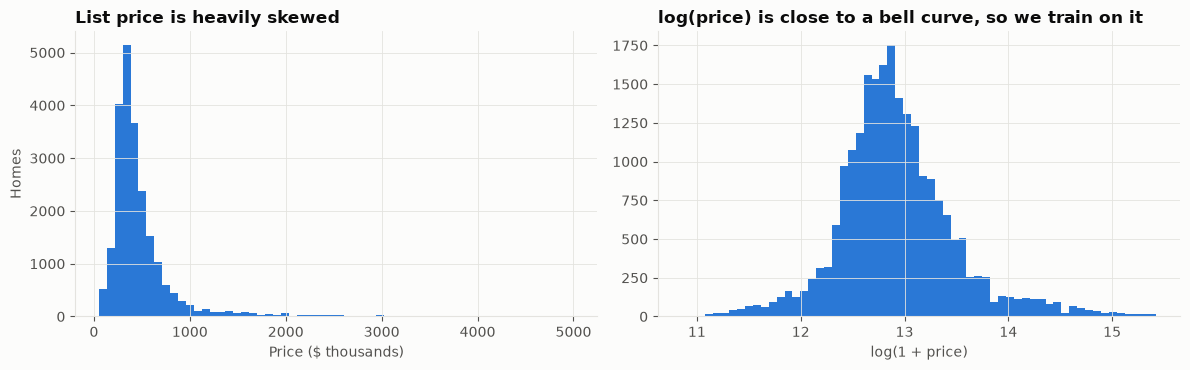

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(df.price / 1e3, bins=60, color=BLUE)
ax[0].set(title="List price is heavily skewed", xlabel="Price ($ thousands)", ylabel="Homes")
ax[1].hist(df.log_price, bins=60, color=BLUE)
ax[1].set(title="log(price) is close to a bell curve, so we train on it", xlabel="log(1 + price)")
plt.tight_layout(); plt.show()

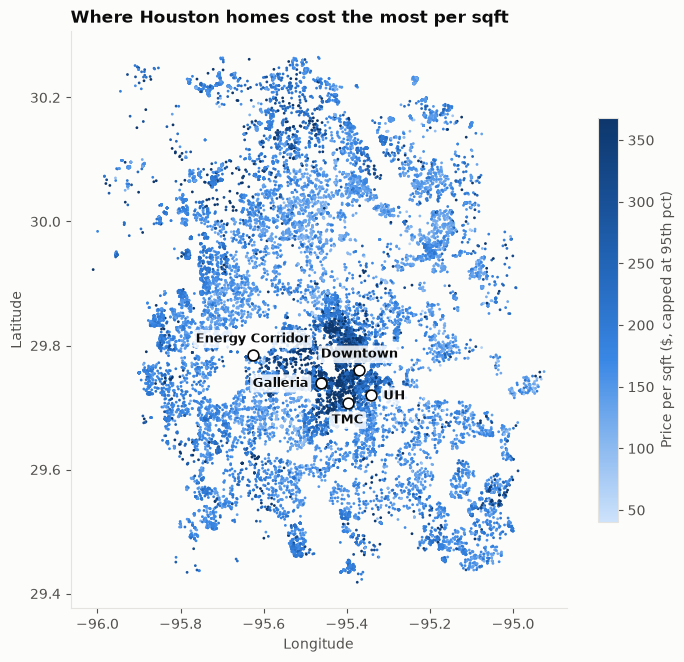

In [7]:
ppsf = df.price / df.livingArea
fig, ax = plt.subplots(figsize=(8, 7.5))
sc = ax.scatter(df.longitude, df.latitude, c=ppsf.clip(upper=ppsf.quantile(0.95)), cmap=BLUE_RAMP, s=4, linewidths=0)
# Hubs sit close together, so each label gets its own direction
LABEL_POS = {"downtown": ((0, 9), "center"), "tmc": ((0, -15), "center"), "galleria": ((-9, -3), "right"),
             "energy_corridor": ((0, 9), "center"), "uh": ((9, -3), "left")}
for name, (lat, lon) in HUBS.items():
    ax.scatter(lon, lat, s=60, color="white", edgecolors=INK, linewidths=1.2, zorder=3)
    offset, ha = LABEL_POS[name]
    label = "TMC" if name == "tmc" else "UH" if name == "uh" else name.replace("_", " ").title()
    ax.annotate(label, (lon, lat), xytext=offset, textcoords="offset points", ha=ha, color=INK, fontsize=9,
                fontweight="bold", bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))
plt.colorbar(sc, ax=ax, shrink=0.7, label="Price per sqft ($, capped at 95th pct)")
ax.set(title="Where Houston homes cost the most per sqft", xlabel="Longitude", ylabel="Latitude")
ax.grid(False); plt.show()

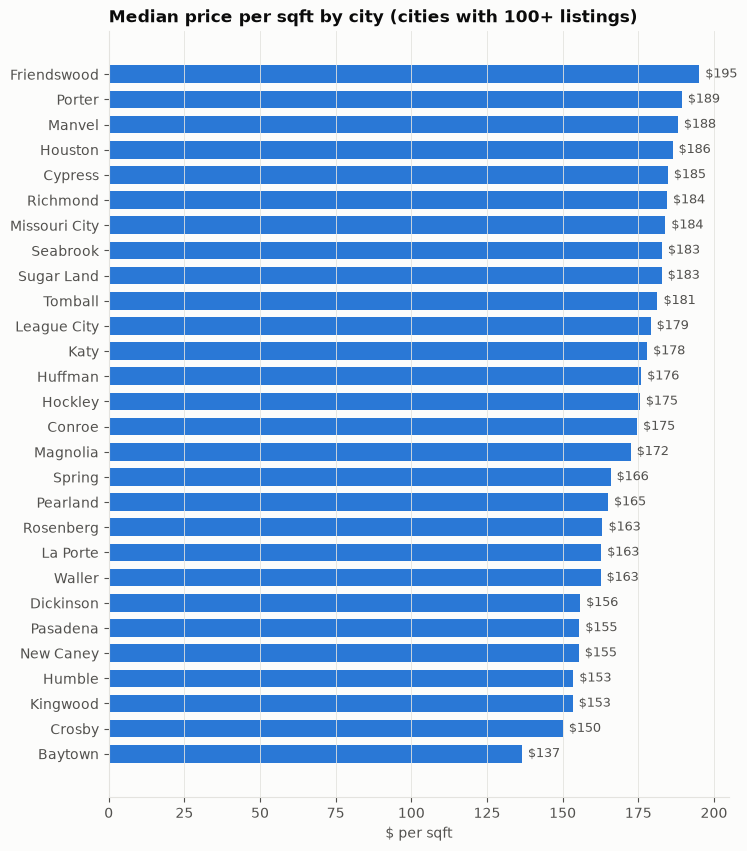

,listings,median_price,median_ppsf
city,,,
Friendswood,167,"$617,900",$195
Porter,421,"$417,000",$189
Manvel,585,"$489,000",$188
Houston,8570,"$349,000",$186
Cypress,1032,"$474,970",$185
Richmond,1119,"$464,900",$184
Missouri City,681,"$469,900",$184
Seabrook,119,"$375,000",$183
Sugar Land,293,"$495,000",$183


In [8]:
city_stats = (df.assign(ppsf=ppsf).groupby("city")
                .agg(listings=("price", "size"), median_price=("price", "median"), median_ppsf=("ppsf", "median")))
top = city_stats[city_stats.listings >= 100].sort_values("median_ppsf")
fig, ax = plt.subplots(figsize=(8, 0.32 * len(top) + 1))
ax.barh(top.index, top.median_ppsf, color=BLUE, height=0.7)
for y, v in enumerate(top.median_ppsf):
    ax.text(v + 2, y, f"${v:,.0f}", va="center", color=INK_2, fontsize=9)
ax.set(title="Median price per sqft by city (cities with 100+ listings)", xlabel="$ per sqft")
ax.grid(axis="y", visible=False); plt.show()
top.sort_values("median_ppsf", ascending=False).style.format({"median_price": "${:,.0f}", "median_ppsf": "${:,.0f}"})

## 5. Features
- **Location:** latitude/longitude, plus straight-line miles to Downtown, the Medical Center, the Galleria, the Energy Corridor and UH.
- **Neighborhood comps:** the median $/sqft of the 10 nearest homes, and that times this home's sqft (a "comps estimate").
  To avoid leakage, a home **never sees its own price**: training homes get comps only from *other folds*, and test homes only from training homes.

In [9]:
def miles_between(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * EARTH_MILES * np.arcsin(np.sqrt(a))

for name, (lat, lon) in HUBS.items():
    df[f"mi_to_{name}"] = miles_between(df.latitude, df.longitude, lat, lon)

HOME_TYPES = {t: i for i, t in enumerate(sorted(df.homeType.unique()))}
df["home_type_code"] = df.homeType.map(HOME_TYPES)

def knn_ppsf(ref, query, k=10):
    # Median $/sqft of the k nearest homes in `ref` to each home in `query`
    tree = BallTree(np.radians(ref[["latitude", "longitude"]].to_numpy()), metric="haversine")
    _, idx = tree.query(np.radians(query[["latitude", "longitude"]].to_numpy()), k=k)
    return np.median((ref.price / ref.livingArea).to_numpy()[idx], axis=1)

def oof_knn_ppsf(frame, k=10, folds=5):
    # Same feature for every row of `frame`, built only from neighbours in the other folds
    out = np.empty(len(frame))
    for fit_idx, hold_idx in KFold(folds, shuffle=True, random_state=SEED).split(frame):
        out[hold_idx] = knn_ppsf(frame.iloc[fit_idx], frame.iloc[hold_idx], k)
    return out

def add_comps(train, test, k=10):
    train, test = train.copy(), test.copy()
    train["knn_ppsf"] = oof_knn_ppsf(train, k)
    test["knn_ppsf"] = knn_ppsf(train, test, k)
    for d in (train, test):
        d["comp_value"] = d.knn_ppsf * d.livingArea
    return train, test

BASIC = ["bedrooms", "bathrooms", "livingArea", "lot_sqft", "yearBuilt", "home_type_code"]
LOCATION = BASIC + ["latitude", "longitude"] + [f"mi_to_{h}" for h in HUBS]
COMPS = LOCATION + ["knn_ppsf", "comp_value"]

train, test = train_test_split(df, test_size=0.2, random_state=SEED)
train, test = add_comps(train.reset_index(drop=True), test.reset_index(drop=True))
print(f"train {len(train):,} homes | test {len(test):,} homes (the model never trains on these)")

train 17,953 homes | test 4,489 homes (the model never trains on these)


## 6. Train & compare models
Same algorithm (gradient-boosted trees) each time; only the inputs change. Errors are in **dollars** on the held-out test homes.

In [10]:
def evaluate(name, y_true, y_pred):
    pct = np.abs(y_pred - y_true) / y_true
    return {"model": name,
            "MAE ($)": mean_absolute_error(y_true, y_pred),
            "RMSE ($)": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R²": r2_score(y_true, y_pred),
            "median % error": 100 * np.median(pct),
            "within 10%": 100 * np.mean(pct <= 0.10)}

def make_model(cols):
    return HistGradientBoostingRegressor(
        max_iter=800, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=20, l2_regularization=1.0,
        early_stopping=True, validation_fraction=0.1, n_iter_no_change=30,
        categorical_features=[c == "home_type_code" for c in cols], random_state=SEED)

y_test = test.price.to_numpy()
rule_ppsf = (train.price / train.livingArea).median()
results = [evaluate("0. Rule of thumb: sqft x median $/sqft", y_test, test.livingArea.to_numpy() * rule_ppsf)]

models, preds = {}, {}
for name, cols in [("1. ML: house facts only", BASIC),
                   ("2. + location & hub distances", LOCATION),
                   ("3. + neighborhood comps", COMPS)]:
    models[name] = make_model(cols).fit(train[cols], train.log_price)
    preds[name] = np.expm1(models[name].predict(test[cols]))
    results.append(evaluate(name, y_test, preds[name]))

results_df = pd.DataFrame(results).set_index("model")
BEST = "3. + neighborhood comps"
first, last = results_df.loc["1. ML: house facts only"], results_df.loc[BEST]
print(f"Adding location + comps cut the typical error from {first['median % error']:.1f}% to {last['median % error']:.1f}% "
      f"and MAE from ${first['MAE ($)']:,.0f} to ${last['MAE ($)']:,.0f}.")
FMT = {"MAE ($)": "${:,.0f}", "RMSE ($)": "${:,.0f}", "R²": "{:.3f}", "median % error": "{:.1f}%", "within 10%": "{:.1f}%"}
results_df.style.format(FMT)

Adding location + comps cut the typical error from 12.8% to 6.8% and MAE from $102,471 to $62,378.


,MAE ($),RMSE ($),R²,median % error,within 10%
model,,,,,
0. Rule of thumb: sqft x median $/sqft,"$137,177","$317,740",0.402,16.2%,32.3%
1. ML: house facts only,"$102,471","$224,758",0.701,12.8%,40.6%
2. + location & hub distances,"$64,956","$161,498",0.846,7.3%,62.2%
3. + neighborhood comps,"$62,378","$156,767",0.855,6.8%,64.5%


**Benchmark against Zillow.** Compared only on test homes that have a real Zestimate.
Zillow's Zestimate for a home on the market uses the list price itself plus far more data, so expect it to win. The honest pitch is how close we get *without* seeing the list price.

In [11]:
has_z = test.has_zestimate.to_numpy() == 1
bench = pd.DataFrame([evaluate("Our model (never sees the list price)", y_test[has_z], preds[BEST][has_z]),
                      evaluate("Zillow Zestimate", y_test[has_z], test.zestimate.to_numpy()[has_z])]).set_index("model")
bench.style.format(FMT)

,MAE ($),RMSE ($),R²,median % error,within 10%
model,,,,,
Our model (never sees the list price),"$60,200","$138,115",0.882,6.8%,64.6%
Zillow Zestimate,"$17,783","$38,928",0.991,3.2%,98.9%


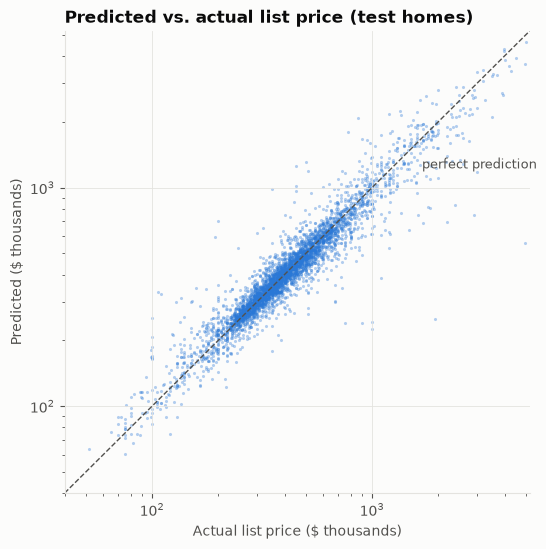

In [12]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test / 1e3, preds[BEST] / 1e3, s=5, color=BLUE, alpha=0.35, linewidths=0)
lims = [40, 5200]
ax.plot(lims, lims, color=INK_2, linewidth=1, linestyle="--")
ax.annotate("perfect prediction", (1500, 1500), xytext=(8, -14), textcoords="offset points", color=INK_2, fontsize=9)
ax.set(xscale="log", yscale="log", xlim=lims, ylim=lims, title="Predicted vs. actual list price (test homes)",
       xlabel="Actual list price ($ thousands)", ylabel="Predicted ($ thousands)")
plt.show()

## 7. What drives Houston prices
Permutation importance: shuffle one input at a time and measure how much worse the model gets. Bigger bar = the model leans on it more.

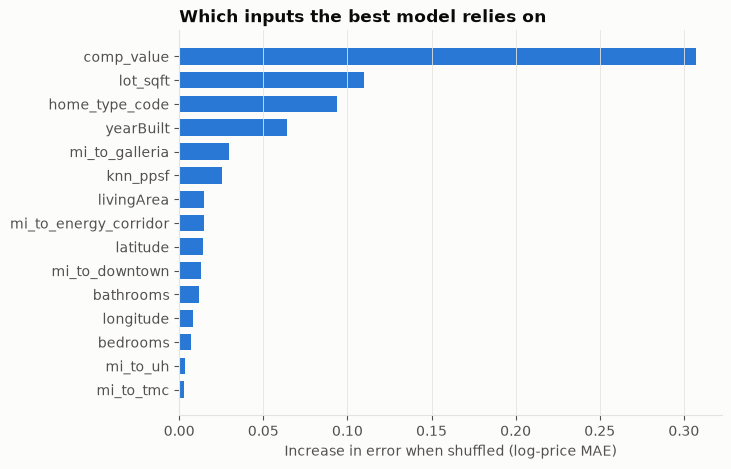

In [13]:
pi = permutation_importance(models[BEST], test[COMPS], test.log_price, n_repeats=5,
                            random_state=SEED, n_jobs=-1, scoring="neg_mean_absolute_error")
imp = pd.Series(pi.importances_mean, index=COMPS).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(imp.index, imp.values, color=BLUE, height=0.7)
ax.set(title="Which inputs the best model relies on", xlabel="Increase in error when shuffled (log-price MAE)")
ax.grid(axis="y", visible=False); plt.show()

## 8. Price check: how does each listing compare with similar homes?
Every home gets a **fair value** from a model that never saw that home (5-fold out-of-fold predictions).
`gap = list price / fair value - 1`.

- **Only rate homes where the model is reliable:** single-family homes and townhouses built 1980 or later, under 1 acre, listed at $150k–$1.2M.
  The first run showed the model is much less accurate for older homes, manufactured and multi-family homes, big lots and price extremes, and that's where nearly all the "too good to be true" gaps came from.
- **15–40% gap:** *below* or *above similar homes*. **40%+:** *check listing*. A gap that big is almost always bad data or something the data can't see (condition, flood damage), not a bargain.

**What this can and can't tell you:** listing data alone can't prove a home is underpriced.
Zillow's Zestimate tracks the list price closely, so it can't confirm a bargain (see `median_list_to_zestimate`: about the same for every group).
`daysOnZillow` only says how long an *active* listing has been up so far, and stale listings get price cuts, so it isn't a clean test either.
Present *below similar homes* as **"worth a closer look: ask the agent why"**, not as "a deal".

In [14]:
def fair_values(frame, cols, folds=5):
    out = np.empty(len(frame))
    for fit_idx, hold_idx in KFold(folds, shuffle=True, random_state=SEED + 1).split(frame):
        tr, ho = add_comps(frame.iloc[fit_idx].reset_index(drop=True), frame.iloc[hold_idx].reset_index(drop=True))
        out[hold_idx] = np.expm1(make_model(cols).fit(tr[cols], tr.log_price).predict(ho[cols]))
    return out

homes = df.copy()
homes["fair_value"] = fair_values(homes, COMPS)
homes["gap_pct"] = 100 * (homes.price / homes.fair_value - 1)
homes["rated"] = (homes.homeType.isin(["SINGLE_FAMILY", "TOWNHOUSE"]) & (homes.yearBuilt >= 1980)
                  & (homes.lot_sqft.isna() | (homes.lot_sqft < 43_560)) & homes.price.between(150_000, 1_200_000))

BELOW, IN_LINE, ABOVE = "Below similar homes", "In line with similar homes", "Above similar homes"
CHECK, NOT_RATED = "Check listing (gap too big to trust)", "Not rated (model less reliable)"
homes["price_check"] = np.select(
    [~homes.rated, homes.gap_pct.abs() >= 40, homes.gap_pct <= -15, homes.gap_pct >= 15],
    [NOT_RATED, CHECK, BELOW, ABOVE], default=IN_LINE)

rated = homes[homes.rated]
print(f"Rated {len(rated):,} of {len(homes):,} homes. Typical error on rated homes: "
      f"{100 * ((rated.price - rated.fair_value).abs() / rated.price).median():.1f}% "
      f"(vs {100 * ((homes.price - homes.fair_value).abs() / homes.price).median():.1f}% on all homes)")

real_z = homes.has_zestimate == 1
(homes.assign(list_to_zestimate=(homes.price / homes.zestimate).where(real_z))
      .groupby("price_check")
      .agg(homes=("price", "size"), median_gap_pct=("gap_pct", "median"),
           median_days_on_zillow=("daysOnZillow", "median"), median_list_to_zestimate=("list_to_zestimate", "median"))
      .reindex([BELOW, IN_LINE, ABOVE, CHECK, NOT_RATED])
      .style.format({"median_gap_pct": "{:+.1f}%", "median_days_on_zillow": "{:.0f}", "median_list_to_zestimate": "{:.3f}"}))

Rated 15,592 of 22,442 homes. Typical error on rated homes: 5.8% (vs 7.1% on all homes)


,homes,median_gap_pct,median_days_on_zillow,median_list_to_zestimate
price_check,,,,
Below similar homes,891,-18.9%,35,1.035
In line with similar homes,13504,-0.5%,34,1.028
Above similar homes,1053,+19.7%,27,1.028
Check listing (gap too big to trust),144,+52.2%,42,1.037
Not rated (model less reliable),6850,+0.4%,44,1.052


## 9. Monthly-cost budget search
Sticker price hides most of the cost in Texas. Total monthly cost = mortgage (principal + interest) + property tax + homeowners insurance + PMI (if under 20% down).
**Assumptions are inputs. Set the mortgage rate to today's rate before demoing.** HOA and flood insurance aren't in this dataset (the raw Kaggle JSON has `hoaFee`), so they're left out and named as limitations.

In [15]:
def monthly_cost(price, rate=0.065, years=30, down_pct=0.10, tax_rate=0.022, insurance_rate=0.010):
    loan = price * (1 - down_pct)
    r, n = rate / 12, years * 12
    parts = {"mortgage": loan * r / (1 - (1 + r) ** -n),
             "property_tax": price * tax_rate / 12,
             "insurance": price * insurance_rate / 12,
             "pmi": loan * 0.005 / 12 if down_pct < 0.20 else loan * 0}
    parts["total"] = sum(parts.values())
    return parts

example = 350_000
print(f"A ${example:,} home, 10% down, 6.5%:")
for k, v in monthly_cost(example).items():
    print(f"  {k:13} ${v:,.0f}/month")

A $350,000 home, 10% down, 6.5%:
  mortgage      $1,991/month
  property_tax  $642/month
  insurance     $292/month
  pmi           $131/month
  total         $3,056/month


In [16]:
#@title Find homes that fit a monthly budget, lowest price vs. similar homes first
BUDGET_PER_MONTH = 3000  #@param {type:"integer"}
DOWN_PAYMENT_PCT = 10    #@param {type:"number"}
MORTGAGE_RATE_PCT = 6.5  #@param {type:"number"}
MIN_BEDS = 3             #@param {type:"integer"}
CITY = "Any"             #@param {type:"string"}

cost = monthly_cost(homes.price, rate=MORTGAGE_RATE_PCT / 100, down_pct=DOWN_PAYMENT_PCT / 100)
view = homes.assign(monthly_total=cost["total"])
mask = (view.monthly_total <= BUDGET_PER_MONTH) & (view.bedrooms >= MIN_BEDS)
if CITY.strip().lower() != "any":
    mask &= view.city.str.lower() == CITY.strip().lower()

matches = view[mask]
checked = matches[matches.price_check.isin([BELOW, IN_LINE, ABOVE])]
print(f"{len(matches):,} homes fit ${BUDGET_PER_MONTH:,}/month with {MIN_BEDS}+ beds. "
      f"{len(checked):,} have a price check; {(checked.price_check == BELOW).sum():,} are below similar homes.")
cols = ["city", "zipcode", "homeType", "bedrooms", "bathrooms", "livingArea", "yearBuilt",
        "price", "fair_value", "gap_pct", "price_check", "monthly_total", "daysOnZillow", "zpid"]
(checked.sort_values("gap_pct")[cols].head(15)
        .style.format({"price": "${:,.0f}", "fair_value": "${:,.0f}", "gap_pct": "{:+.1f}%",
                       "monthly_total": "${:,.0f}", "livingArea": "{:,.0f}", "yearBuilt": "{:.0f}"}))

7,076 homes fit $3,000/month with 3+ beds. 4,854 have a price check; 320 are below similar homes.


,city,zipcode,homeType,bedrooms,bathrooms,livingArea,yearBuilt,price,fair_value,gap_pct,price_check,monthly_total,daysOnZillow,zpid
4409,Stafford,77477,SINGLE_FAMILY,3.000000,2.000000,"2,264",1982,"$190,000","$304,305",-37.6%,Below similar homes,"$1,659",32,28411488
17828,Shoreacres,77571,SINGLE_FAMILY,3.000000,2.000000,"1,824",2013,"$338,500","$536,005",-36.8%,Below similar homes,"$2,955",172,27832226
20444,Manvel,77578,SINGLE_FAMILY,3.000000,2.000000,"2,320",2022,"$272,000","$430,521",-36.8%,Below similar homes,"$2,375",55,2054901558
14841,Houston,77009,SINGLE_FAMILY,3.000000,3.000000,"1,781",2021,"$325,000","$513,641",-36.7%,Below similar homes,"$2,837",30,329224738
17999,Dickinson,77539,SINGLE_FAMILY,4.000000,2.000000,"2,272",2018,"$319,000","$500,231",-36.2%,Below similar homes,"$2,785",11,27691371
8314,Tomball,77375,SINGLE_FAMILY,5.000000,3.000000,"3,540",2005,"$289,000","$448,656",-35.6%,Below similar homes,"$2,523",19,80559592
1139,Houston,77091,SINGLE_FAMILY,4.000000,3.000000,"1,645",2024,"$228,000","$351,978",-35.2%,Below similar homes,"$1,991",12,350745333
12202,Houston,77020,TOWNHOUSE,3.000000,3.000000,"1,790",1981,"$185,000","$285,552",-35.2%,Below similar homes,"$1,615",59,27743800
3965,Houston,77071,SINGLE_FAMILY,3.000000,3.000000,"2,532",2021,"$254,990","$390,804",-34.8%,Below similar homes,"$2,226",102,28232157
662,Conroe,77385,SINGLE_FAMILY,3.000000,3.000000,"2,219",1996,"$299,500","$456,922",-34.5%,Below similar homes,"$2,615",62,296387854


Look up any row on Zillow at `https://www.zillow.com/homedetails/<zpid>_zpid/` to show a real listing in the demo.

## 10. Save the model for an app
Trains the final model on **all** homes and saves it with everything an app (Streamlit, etc.) needs to price a new address.

In [17]:
import joblib
full = df.copy()
full["knn_ppsf"] = oof_knn_ppsf(full)
full["comp_value"] = full.knn_ppsf * full.livingArea
final_model = make_model(COMPS).fit(full[COMPS], full.log_price)

os.makedirs("artifacts", exist_ok=True)
joblib.dump({"model": final_model, "features": COMPS, "home_types": HOME_TYPES, "hubs": HUBS,
             "comps_ref": df[["latitude", "longitude", "price", "livingArea"]]}, "artifacts/price_model.joblib")
homes.to_csv("artifacts/homes_with_fair_value.csv", index=False)
results_df.to_csv("artifacts/model_comparison.csv")
shutil.make_archive("artifacts", "zip", "artifacts")
print("Saved:", os.listdir("artifacts"))
try:
    from google.colab import files
    files.download("artifacts.zip")
except ImportError:
    print("Not in Colab: files are in ./artifacts")

Saved: ['model_comparison.csv', 'price_model.joblib', 'homes_with_fair_value.csv']
Not in Colab: files are in ./artifacts


## Pitch notes (fill in from your results)
- **Problem:** Houston buyers judge homes by sticker price, but location and Texas property taxes decide what they can afford.
- **What we built:** a model that prices a home from its facts + location (median error **__%**, **__%** of homes within 10%), a price check against similar homes, and a monthly-budget search.
- **Proof it improved:** the before/after table in step 6 (rule of thumb → facts only → + location → + comps).
- **Persona demo:** a UH grad with $3,000/month → step 9 form → open one "below similar homes" listing on Zillow and ask *why* it's cheaper.
- **What we learned (judges like this):** our first version flagged "bargains" that were really model mistakes (huge lots, old homes, manufactured homes). Checking against Zillow showed it, so we now rate only homes where the model is reliable (~6% typical error) and call big gaps "worth a closer look", not "deals".
- **Limitations (say them):** list prices aren't sale prices; one snapshot of 2024 listings; the model can't see condition or flood history; new-build communities share coordinates, which flatters comps; HOA and flood insurance aren't included; tax and insurance rates are averages.